# Lab 03 – Tiny Transformer Improvement Experiments
 
**Purpose:** Improve character-level story generation **without modifying** the original Lab 03 notebook.  
**Dataset:** [roneneldan/TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories)  
**Source code basis:** Adapted from the Lab 03 notebook and the lecturer-supplied Tiny Transformer examples.

### Experiments
1. **Decoding settings:** Reload the original 2-layer checkpoint; compare temperature and top-k **without retraining**.
2. **Enhanced training:** Train a fresh 2-layer model on more stories, longer context and more updates.
3. **Optional scale-up:** Train a larger model in a separate run (**off by default**).
4. **Comparison:** Evaluate checkpoints on the **same held-out TinyStories validation text**, and examine samples using the same prompts and decoding settings.




### Environment, paths and experiment settings

In [1]:
import math
import json
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

cwd = Path.cwd().resolve()
if cwd.name == "notebooks":
    LAB_DIR = cwd.parent
elif cwd.name == "Lab-03-Tiny-Transformer":
    LAB_DIR = cwd
elif (cwd / "Lab-03-Tiny-Transformer").is_dir():
    LAB_DIR = cwd / "Lab-03-Tiny-Transformer"
else:
    raise FileNotFoundError("Open VS Code in the portfolio root or Lab-03-Tiny-Transformer folder.")

BASELINE_CHECKPOINT = LAB_DIR / "checkpoints" / "tiny_transformer_checkpoint.pt"
RESULTS_DIR = LAB_DIR / "results" / "improvement_experiments"
CHECKPOINT_DIR = LAB_DIR / "checkpoints" / "improvement_experiments"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

QUICK_TEST = False      
RUN_ADVANCED = False     # Optional larger-model experiment; can be demanding on CPU

TRAIN_STORIES = 2000 if not QUICK_TEST else 80
VALIDATION_STORIES = 100 if not QUICK_TEST else 20
BLOCK_SIZE = 128 if not QUICK_TEST else 64
BATCH_SIZE = 16 if not QUICK_TEST else 4
EPOCHS = 20 if not QUICK_TEST else 1
STEPS_PER_EPOCH = 150 if not QUICK_TEST else 3
VAL_BATCHES = 10 if not QUICK_TEST else 2
LEARNING_RATE = 0.001

EMBED_DIM = 64
NUM_HEADS = 2
NUM_LAYERS = 2
FF_DIM = 128
DROPOUT = 0.10

RUN_LABEL = "quicktest" if QUICK_TEST else "enhanced_2000stories_20epochs"
PROMPTS = ["Once upon a time", "The little boy", "One day, a little girl named Lily"]

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Lab directory:", LAB_DIR)
print("Quick test mode:", QUICK_TEST)
print("Enhanced run label:", RUN_LABEL)

c:\Users\Owner\Downloads\LLM-Practical-Portfolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.15.0+cpu
Device: cpu
Lab directory: C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer
Quick test mode: False
Enhanced run label: enhanced_2000stories_20epochs


## 1. Reusable model and generation functions

The architecture is **the same as the original Lab 03 notebook**, including embeddings, causal masked multi-head attention, feed-forward layers, residual connections and layer normalization. Keeping the model class compatible lets us load your earlier checkpoint.

**Tokenizer:** Character IDs use `1..N`; ID `0` is the unknown-character token. The tokenizer is always reconstructed from the character list saved alongside the model.

In [2]:
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim, num_heads=num_heads, dropout=dropout,
            batch_first=True
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, ff_dim), nn.GELU(),
            nn.Linear(ff_dim, embed_dim)
        )

    def forward(self, x, causal_mask):
        attended, _ = self.attention(x, x, x, attn_mask=causal_mask,
                                     need_weights=False)
        x = self.norm1(x + self.dropout(attended))
        x = self.norm2(x + self.dropout(self.feed_forward(x)))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, embed_dim=64,
                 num_heads=2, num_layers=2, ff_dim=128, dropout=0.1):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads")
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(block_size, embed_dim)
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, token_ids):
        _, length = token_ids.shape
        if length > self.block_size:
            raise ValueError("Input sequence exceeds the model's context length")
        positions = torch.arange(length, device=token_ids.device)
        hidden = self.token_embedding(token_ids) + self.position_embedding(positions)
        causal_mask = torch.triu(
            torch.ones(length, length, dtype=torch.bool, device=token_ids.device),
            diagonal=1
        )
        for block in self.blocks:
            hidden = block(hidden, causal_mask)
        return self.lm_head(self.final_norm(hidden))


def make_tokenizer(chars):
    stoi = {ch: i + 1 for i, ch in enumerate(chars)}
    itos = {i + 1: ch for i, ch in enumerate(chars)}
    itos[0] = "?"
    return stoi, itos


def encode_text(text, stoi):
    return [stoi.get(ch, 0) for ch in text]


def decode_ids(ids, itos):
    return "".join(itos.get(int(i), "?") for i in ids)


@torch.no_grad()
def generate_text(net, prompt, stoi, itos, max_new_chars=200,
                  temperature=0.6, top_k=5, seed=123):
    if not prompt.strip():
        raise ValueError("Prompt must not be empty")
    if temperature <= 0:
        raise ValueError("Temperature must be positive")

    net.eval()
    tokens = torch.tensor([encode_text(prompt, stoi)], dtype=torch.long,
                          device=DEVICE)
    sampling_rng = torch.Generator(device=DEVICE).manual_seed(seed)

    for _ in range(max_new_chars):
        logits = net(tokens[:, -net.block_size:])[:, -1, :] / temperature
        if top_k is not None:
            k = min(max(1, int(top_k)), logits.size(-1))
            values, indices = torch.topk(logits, k, dim=-1)
            filtered = torch.full_like(logits, -float("inf"))
            logits = filtered.scatter(1, indices, values)
        probabilities = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probabilities, 1, generator=sampling_rng)
        tokens = torch.cat((tokens, next_id), dim=1)

    return decode_ids(tokens[0].tolist(), itos)

print("Model architecture and generation functions loaded.")

Model architecture and generation functions loaded.


## 2. Experiment A- Generation settings on the saved baseline

**Purpose:** Check whether changing `temperature` and `top_k` improves readability **without changing the trained weights**.

- Lower temperature tends to favour more probable next characters; it can reduce unusual text but increase repetition.
- Smaller top-k limits choices to a smaller set of predicted characters.
- All samples use the **same prompt and random seed** for a more consistent demonstration.

In [5]:
baseline_model = None
baseline_stoi = None
baseline_itos = None
baseline_characters = None

if not BASELINE_CHECKPOINT.exists():
    print("Baseline checkpoint not found:", BASELINE_CHECKPOINT)
    print("Experiment A skipped. Continue to Experiment B.")
else:
    saved = torch.load(BASELINE_CHECKPOINT, map_location=DEVICE, weights_only=True)
    baseline_model = TinyTransformer(**saved["config"]).to(DEVICE)
    baseline_model.load_state_dict(saved["model_state_dict"])
    baseline_model.eval()
    baseline_characters = saved["chars"]
    baseline_stoi, baseline_itos = make_tokenizer(baseline_characters)

    print("Loaded baseline checkpoint:", BASELINE_CHECKPOINT)
    print("Baseline context size:", baseline_model.block_size)
    print("Baseline parameters:", sum(p.numel() for p in baseline_model.parameters()))

    decoding_settings = [
        ("Original sampling", 0.8, 10),
        ("More conservative", 0.5, 5),
        ("Intermediate", 0.6, 5),
        ("Moderate", 0.7, 10)

    ]
    decoding_rows = []
    for label, temperature, top_k in decoding_settings:
        story = generate_text(
            baseline_model, "Once upon a time", baseline_stoi, baseline_itos,  temperature=temperature, top_k=top_k, seed=123
        )
        decoding_rows.append({"setting": label, "temperature": temperature,
                              "top_k": top_k, "generated_story": story})
        print(f"\n--- {label} | temperature={temperature} | top_k={top_k} ---")
        print(story)


    decoding_df = pd.DataFrame(decoding_rows)
    decoding_df.to_csv(RESULTS_DIR / "baseline_decoding_comparison.csv", index=False)
    display(decoding_df[["setting", "temperature", "top_k"]])


Loaded baseline checkpoint: C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer\checkpoints\tiny_transformer_checkpoint.pt
Baseline context size: 64
Baseline parameters: 80714

--- Original sampling | temperature=0.8 | top_k=10 ---
Once upon a time. He ging he sed canle so sherand buld to the wes was and sand sanderound or and. Hed aned on a the salk was was oler the she pon ing. The so be wame. He thagand st to to alland to bene bithy ated and

--- More conservative | temperature=0.5 | top_k=5 ---
Once upon a time the sore was and and so to thand he the bine was was and sand sand to was the was and the the was thas so he buld and ther the sas st sas and an was and the and sto the and and to he a she thas and t

--- Intermediate | temperature=0.6 | top_k=5 ---
Once upon a time bered he was and and so to thand he the bined and and this. The bome shind the to the the be sme be ald was was and a ther the sand and sher a to and and ariented she to the the bup and at th

,setting,temperature,top_k
0,Original sampling,0.8,10
1,More conservative,0.5,5
2,Intermediate,0.6,5
3,Moderate,0.7,10


## 3. Experiment B – Train an enhanced 2-layer Transformer

**Purpose:** Give the same small architecture more experience by using **more TinyStories training examples**, a **128-character context**, and **more gradient updates**.

- Original notebook: 600 selected stories, 64-character context, 2 layers, 12 epochs and 50 steps per epoch in your latest run.
- Enhanced full run: 2,000 training stories, 128-character context, 2 layers, 20 epochs and 150 steps per epoch.
- The **official `validation` split** of TinyStories is separate from the original dataset's `train` split; it is used here to avoid training/validation story overlap.
- Recreate the character vocabulary **only from the training stories**; unseen validation characters become unknown token ID `0`.

In [6]:
# Load only a small part of TinyStories, not the entire dataset.
training_dataset = load_dataset(
    "roneneldan/TinyStories", split=f"train[:{TRAIN_STORIES}]"
)
validation_dataset = load_dataset(
    "roneneldan/TinyStories", split=f"validation[:{VALIDATION_STORIES}]"
)

train_stories = [item["text"] for item in training_dataset if item["text"].strip()]
val_stories = [item["text"] for item in validation_dataset if item["text"].strip()]
train_text = "\n\n".join(train_stories)
val_text = "\n\n".join(val_stories)

chars = sorted(set(train_text))
stoi, itos = make_tokenizer(chars)
vocab_size = len(chars) + 1
train_ids = torch.tensor(encode_text(train_text, stoi), dtype=torch.long)
val_ids = torch.tensor(encode_text(val_text, stoi), dtype=torch.long)

assert len(train_ids) > BLOCK_SIZE + 1 and len(val_ids) > BLOCK_SIZE + 1
print("Training stories:", len(train_stories))
print("Validation stories:", len(val_stories))
print("Training characters:", len(train_ids))
print("Validation characters:", len(val_ids))
print("Vocabulary size:", vocab_size)
print("Unseen validation characters:", sum(ch not in stoi for ch in val_text))
print("Sample training story:\n", train_stories[0][:400])

Training stories: 2000
Validation stories: 100
Training characters: 1704918
Validation characters: 69909
Vocabulary size: 81
Unseen validation characters: 0
Sample training story:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

To


### Training, validation and checkpoint functions

The loss is **next-character cross-entropy**. Evaluation uses fixed, randomly sampled validation windows. Training uses AdamW, backpropagation and gradient clipping. For repeatability, training samples are drawn using a seeded random generator.

Checkpoints store the model weights, configuration and character vocabulary. The best validation-loss weights within the run are used for generation and final evaluation.

In [7]:
def random_batch(data, context_size, batch_size, generator):
    starts = torch.randint(0, len(data) - context_size, (batch_size,),
                           generator=generator)
    x = torch.stack([data[i:i + context_size] for i in starts]).to(DEVICE)
    y = torch.stack([data[i + 1:i + context_size + 1] for i in starts]).to(DEVICE)
    return x, y


def fixed_windows(data, context_size, batch_size, batches=10, seed=123):
    rng = torch.Generator().manual_seed(seed)
    starts_list = [
        torch.randint(0, len(data) - context_size, (batch_size,), generator=rng)
        for _ in range(batches)
    ]
    return starts_list


@torch.no_grad()
def evaluate_model(net, data, context_size, starts_list):
    net.eval()
    losses = []
    for starts in starts_list:
        x = torch.stack([data[i:i + context_size] for i in starts]).to(DEVICE)
        y = torch.stack([data[i + 1:i + context_size + 1] for i in starts]).to(DEVICE)
        logits = net(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                               y.reshape(-1))
        losses.append(loss.item())
    return sum(losses) / len(losses)


def train_model(net, train_data, validation_data, context_size,
                batch_size, epochs, steps_per_epoch, learning_rate, val_batches):
    optimizer = torch.optim.AdamW(net.parameters(), lr=learning_rate)
    train_rng = torch.Generator().manual_seed(SEED + 1)
    validation_windows = fixed_windows(validation_data, context_size,
                                       batch_size, val_batches, SEED + 2)
    history = []
    best_validation_loss = float("inf")
    best_weights = None

    for epoch in range(1, epochs + 1):
        net.train()
        total_loss = 0.0
        for _ in range(steps_per_epoch):
            x, y = random_batch(train_data, context_size, batch_size, train_rng)
            logits = net(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   y.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        train_loss = total_loss / steps_per_epoch
        val_loss = evaluate_model(net, validation_data, context_size,
                                  validation_windows)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": val_loss})
        print(f"Epoch {epoch:02d} | Train loss: {train_loss:.4f} | Validation loss: {val_loss:.4f}")

        if val_loss < best_validation_loss:
            best_validation_loss = val_loss
            best_weights = {name: value.detach().cpu().clone()
                            for name, value in net.state_dict().items()}

    net.load_state_dict(best_weights)
    net.eval()
    return pd.DataFrame(history), best_validation_loss


def plot_learning_curves(history, output_path, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["epoch"], history["train_loss"], label="Training loss")
    plt.plot(history["epoch"], history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()


def save_checkpoint(path, net, config, vocab_chars, details):
    torch.save({"model_state_dict": net.state_dict(), "config": config,
                "chars": vocab_chars, "details": details}, path)
    print("Saved checkpoint:", path)

print("Training and evaluation functions ready.")

Training and evaluation functions ready.


Enhanced model parameters: 85713
Epoch 01 | Train loss: 2.7837 | Validation loss: 2.4285
Epoch 02 | Train loss: 2.3986 | Validation loss: 2.3496
Epoch 03 | Train loss: 2.3374 | Validation loss: 2.2956
Epoch 04 | Train loss: 2.2774 | Validation loss: 2.2102
Epoch 05 | Train loss: 2.1881 | Validation loss: 2.0996
Epoch 06 | Train loss: 2.0963 | Validation loss: 1.9954
Epoch 07 | Train loss: 2.0272 | Validation loss: 1.9052
Epoch 08 | Train loss: 1.9690 | Validation loss: 1.8440
Epoch 09 | Train loss: 1.9268 | Validation loss: 1.7863
Epoch 10 | Train loss: 1.8836 | Validation loss: 1.7357
Epoch 11 | Train loss: 1.8572 | Validation loss: 1.6945
Epoch 12 | Train loss: 1.8319 | Validation loss: 1.6588
Epoch 13 | Train loss: 1.8041 | Validation loss: 1.6201
Epoch 14 | Train loss: 1.7835 | Validation loss: 1.5900
Epoch 15 | Train loss: 1.7575 | Validation loss: 1.5705
Epoch 16 | Train loss: 1.7421 | Validation loss: 1.5522
Epoch 17 | Train loss: 1.7214 | Validation loss: 1.5221
Epoch 18 | Trai

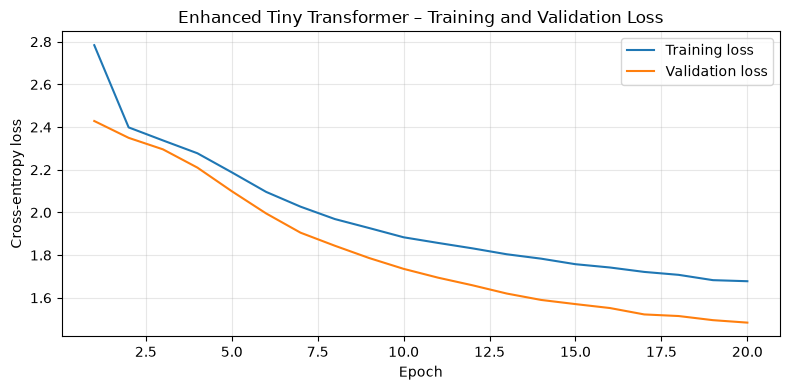

Best enhanced validation loss: 1.4837
Character-level perplexity: 4.4094
Saved checkpoint: C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer\checkpoints\improvement_experiments\enhanced_2000stories_20epochs.pt


In [8]:
enhanced_config = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "embed_dim": EMBED_DIM,
    "num_heads": NUM_HEADS,
    "num_layers": NUM_LAYERS,
    "ff_dim": FF_DIM,
    "dropout": DROPOUT
}

torch.manual_seed(SEED)
enhanced_model = TinyTransformer(**enhanced_config).to(DEVICE)
print("Enhanced model parameters:", sum(p.numel() for p in enhanced_model.parameters()))

enhanced_history, enhanced_best_loss = train_model(
    enhanced_model, train_ids, val_ids,
    context_size=BLOCK_SIZE, batch_size=BATCH_SIZE,
    epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH,
    learning_rate=LEARNING_RATE, val_batches=VAL_BATCHES
)

history_path = RESULTS_DIR / f"{RUN_LABEL}_training_history.csv"
enhanced_history.to_csv(history_path, index=False)
plot_learning_curves(
    enhanced_history, RESULTS_DIR / f"{RUN_LABEL}_loss_curves.png",
    "Enhanced Tiny Transformer – Training and Validation Loss"
)

print("Best enhanced validation loss:", round(enhanced_best_loss, 4))
print("Character-level perplexity:", round(math.exp(enhanced_best_loss), 4))

checkpoint_path = CHECKPOINT_DIR / f"{RUN_LABEL}.pt"
save_checkpoint(
    checkpoint_path, enhanced_model, enhanced_config, chars,
    {"training_stories": len(train_stories),
     "validation_stories": len(val_stories),
     "epochs": EPOCHS, "steps_per_epoch": STEPS_PER_EPOCH,
     "batch_size": BATCH_SIZE, "seed": SEED,
     "best_validation_loss": enhanced_best_loss}
)

### Generate text from the enhanced model

In [9]:
generation_rows = []
for prompt in PROMPTS:
    improved = generate_text(
        enhanced_model, prompt, stoi, itos,
        max_new_chars=200, temperature=0.6, top_k=5, seed=123
    )
    print(f"\n--- Enhanced model | Prompt: {prompt} ---\n{improved}")
    generation_rows.append({"model": RUN_LABEL, "prompt": prompt,
                            "temperature": 0.6, "top_k": 5,
                            "generated_text": improved})

    if baseline_model is not None:
        original = generate_text(
            baseline_model, prompt, baseline_stoi, baseline_itos,
            max_new_chars=200, temperature=0.6, top_k=5, seed=123
        )
        generation_rows.append({"model": "original_baseline", "prompt": prompt,
                                "temperature": 0.6, "top_k": 5,
                                "generated_text": original})
        print(f"\n--- Original baseline | Same prompt/decoding ---\n{original}")

samples_df = pd.DataFrame(generation_rows)
samples_df.to_csv(RESULTS_DIR / f"{RUN_LABEL}_generation_comparison.csv", index=False)
print("\nSaved generation samples.")


--- Enhanced model | Prompt: Once upon a time ---
Once upon a time. He says a with they was a pred. She saw the she wanted to he she were he wanted his the back something and the could and said, "What seeple was sad his and wanted to had the was to she he prould to 

--- Original baseline | Same prompt/decoding ---
Once upon a time bered he was and and so to thand he the bined and and this. The bome shind the to the the be sme be ald was was and a ther the sand and sher a to and and ariented she to the the bup and at thasked st

--- Enhanced model | Prompt: The little boy ---
The little boy. The loved to started the with to be buttle ground the be be with he plout. She what was and so was a pred and the was a little bear the box was saw his a pring the park. She was the prout and the bo

--- Original baseline | Same prompt/decoding ---
The little boy the sone was and and so his a ther and the she sand the was sas oome shimer and. He buped and was thas smiden was an the she was sas was

## 4. Compare models on a common held-out dataset

In [10]:
# Both models support a 64-character context, including the enhanced 128-character model.
EVAL_CONTEXT = 64
EVAL_BATCHES = 10 if not QUICK_TEST else 2
EVAL_BATCH_SIZE = 16 if not QUICK_TEST else 4
# Select common evaluation positions from the same held-out raw validation text.
common_start_batches = fixed_windows(
    torch.zeros(len(val_text), dtype=torch.long), EVAL_CONTEXT,
    EVAL_BATCH_SIZE, EVAL_BATCHES, seed=2026
)

comparison_rows = []
models_to_compare = [
    (RUN_LABEL, enhanced_model, stoi),
]
if baseline_model is not None:
    models_to_compare.insert(0, ("Original 2-layer baseline", baseline_model, baseline_stoi))

for label, net, model_stoi in models_to_compare:
    encoded_validation = torch.tensor(encode_text(val_text, model_stoi),
                                      dtype=torch.long)
    val_loss = evaluate_model(net, encoded_validation, EVAL_CONTEXT,
                              common_start_batches)
    missing_count = sum(ch not in model_stoi for ch in val_text)
    comparison_rows.append({
        "model": label,
        "common_validation_loss": val_loss,
        "common_char_perplexity": math.exp(val_loss),
        "unknown_validation_characters": missing_count,
        "parameters": sum(p.numel() for p in net.parameters()),
        "evaluation_context": EVAL_CONTEXT
    })

common_comparison = pd.DataFrame(comparison_rows)
display(common_comparison.round(4))
common_comparison.to_csv(RESULTS_DIR / f"{RUN_LABEL}_common_validation_comparison.csv", index=False)

print("\nThese results use the same validation text and 64-character evaluation context.")
print("Different training budgets and vocabularies still limit causal conclusions.")

,model,common_validation_loss,common_char_perplexity,unknown_validation_characters,parameters,evaluation_context
0,Original 2-layer baseline,2.0662,7.8948,0,80714,64
1,enhanced_2000stories_20epochs,1.5160,4.5539,0,85713,64



These results use the same validation text and 64-character evaluation context.
Different training budgets and vocabularies still limit causal conclusions.


## 6. Verify the enhanced checkpoint reloads

In [11]:
# Only reload checkpoints that you created or otherwise trust.
restored = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
restored_model = TinyTransformer(**restored["config"]).to(DEVICE)
restored_model.load_state_dict(restored["model_state_dict"])
restored_model.eval()
restored_stoi, restored_itos = make_tokenizer(restored["chars"])

prompt = "Once upon a time"
original_output = generate_text(
    enhanced_model, prompt, stoi, itos,
    temperature=0.6, top_k=5, seed=123
)
reloaded_output = generate_text(
    restored_model, prompt, restored_stoi, restored_itos,
    temperature=0.6, top_k=5, seed=123
)
assert original_output == reloaded_output, "Reloaded output differs. Check tokenizer or checkpoint."
print("Checkpoint reload: PASSED")
print("Saved file:", checkpoint_path)
print("Generated text after reload:\n", reloaded_output)

Checkpoint reload: PASSED
Saved file: C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer\checkpoints\improvement_experiments\enhanced_2000stories_20epochs.pt
Generated text after reload:
 Once upon a time. He says a with they was a pred. She saw the she wanted to he she were he wanted his the back something and the could and said, "What seeple was sad his and wanted to had the was to she he prould to 
